# Breast Cancer Classification: Clustering, PCA and Optimized Logistic Regression

In [1]:
!pip install -q pygad

In [2]:
import time
from typing import Any, cast

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pygad
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, adjusted_rand_score, confusion_matrix, f1_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import Bunch

## 1. Load the data

In [3]:
data = cast(Bunch, load_breast_cancer())

X = data.data
y = data.target
feature_names = list(data.feature_names)
class_names = [str(name) for name in data.target_names]

df = pd.DataFrame(X, columns=feature_names).assign(target=y)
print('X:', X.shape, '| y:', y.shape)
print('Classes:', dict(zip(class_names, np.bincount(y).tolist())))
df.head()

X: (569, 30) | y: (569,)
Classes: {'malignant': 212, 'benign': 357}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## 2. Pairwise scatter plots of the target and the features

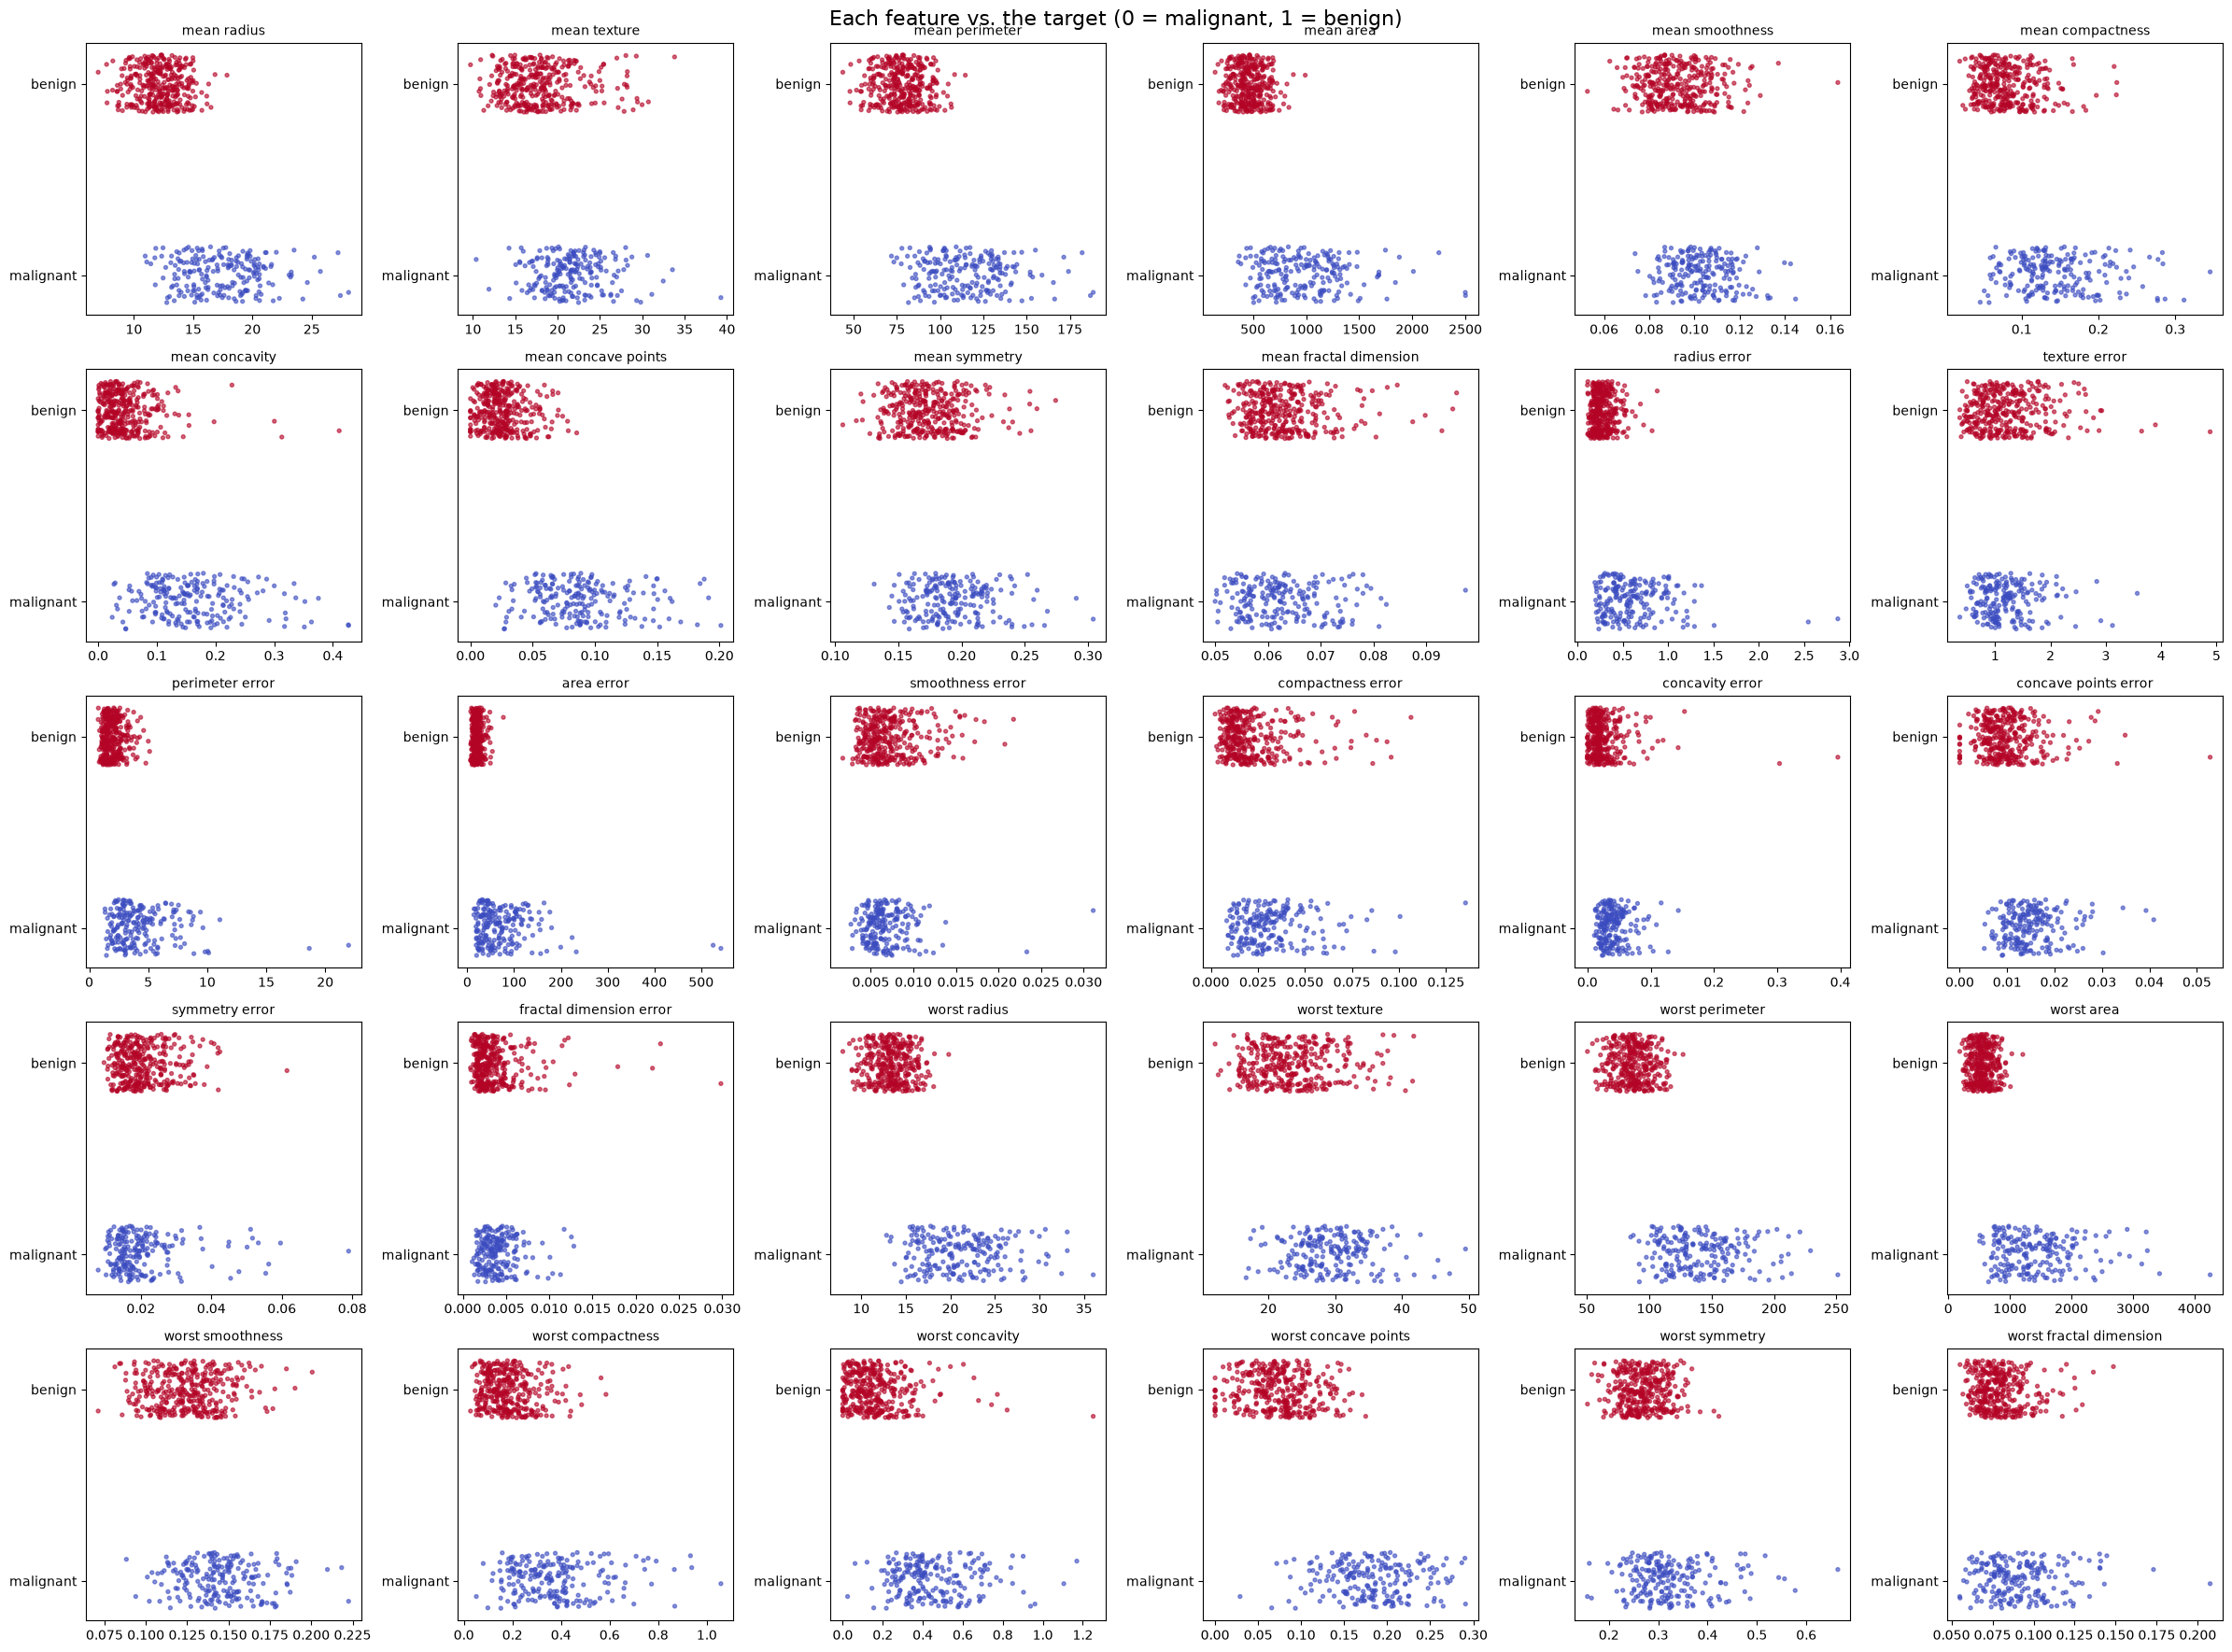

In [10]:
rng = np.random.default_rng(42)
jitter = rng.uniform(-0.15, 0.15, len(y))

fig, axes = plt.subplots(5, 6, figsize=(24, 18))
for ax, feature in zip(axes.ravel(), feature_names):
  ax.scatter(df[feature], y + jitter, c=y, cmap='coolwarm', s=8, alpha=0.6)
  ax.set_title(feature, fontsize=10)
  ax.set_yticks([0, 1], class_names)

fig.suptitle('Each feature vs. the target (0 = malignant, 1 = benign)', fontsize=16)
plt.tight_layout()
plt.show()

Features most correlated with the target:
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
worst area             -0.734
dtype: float64


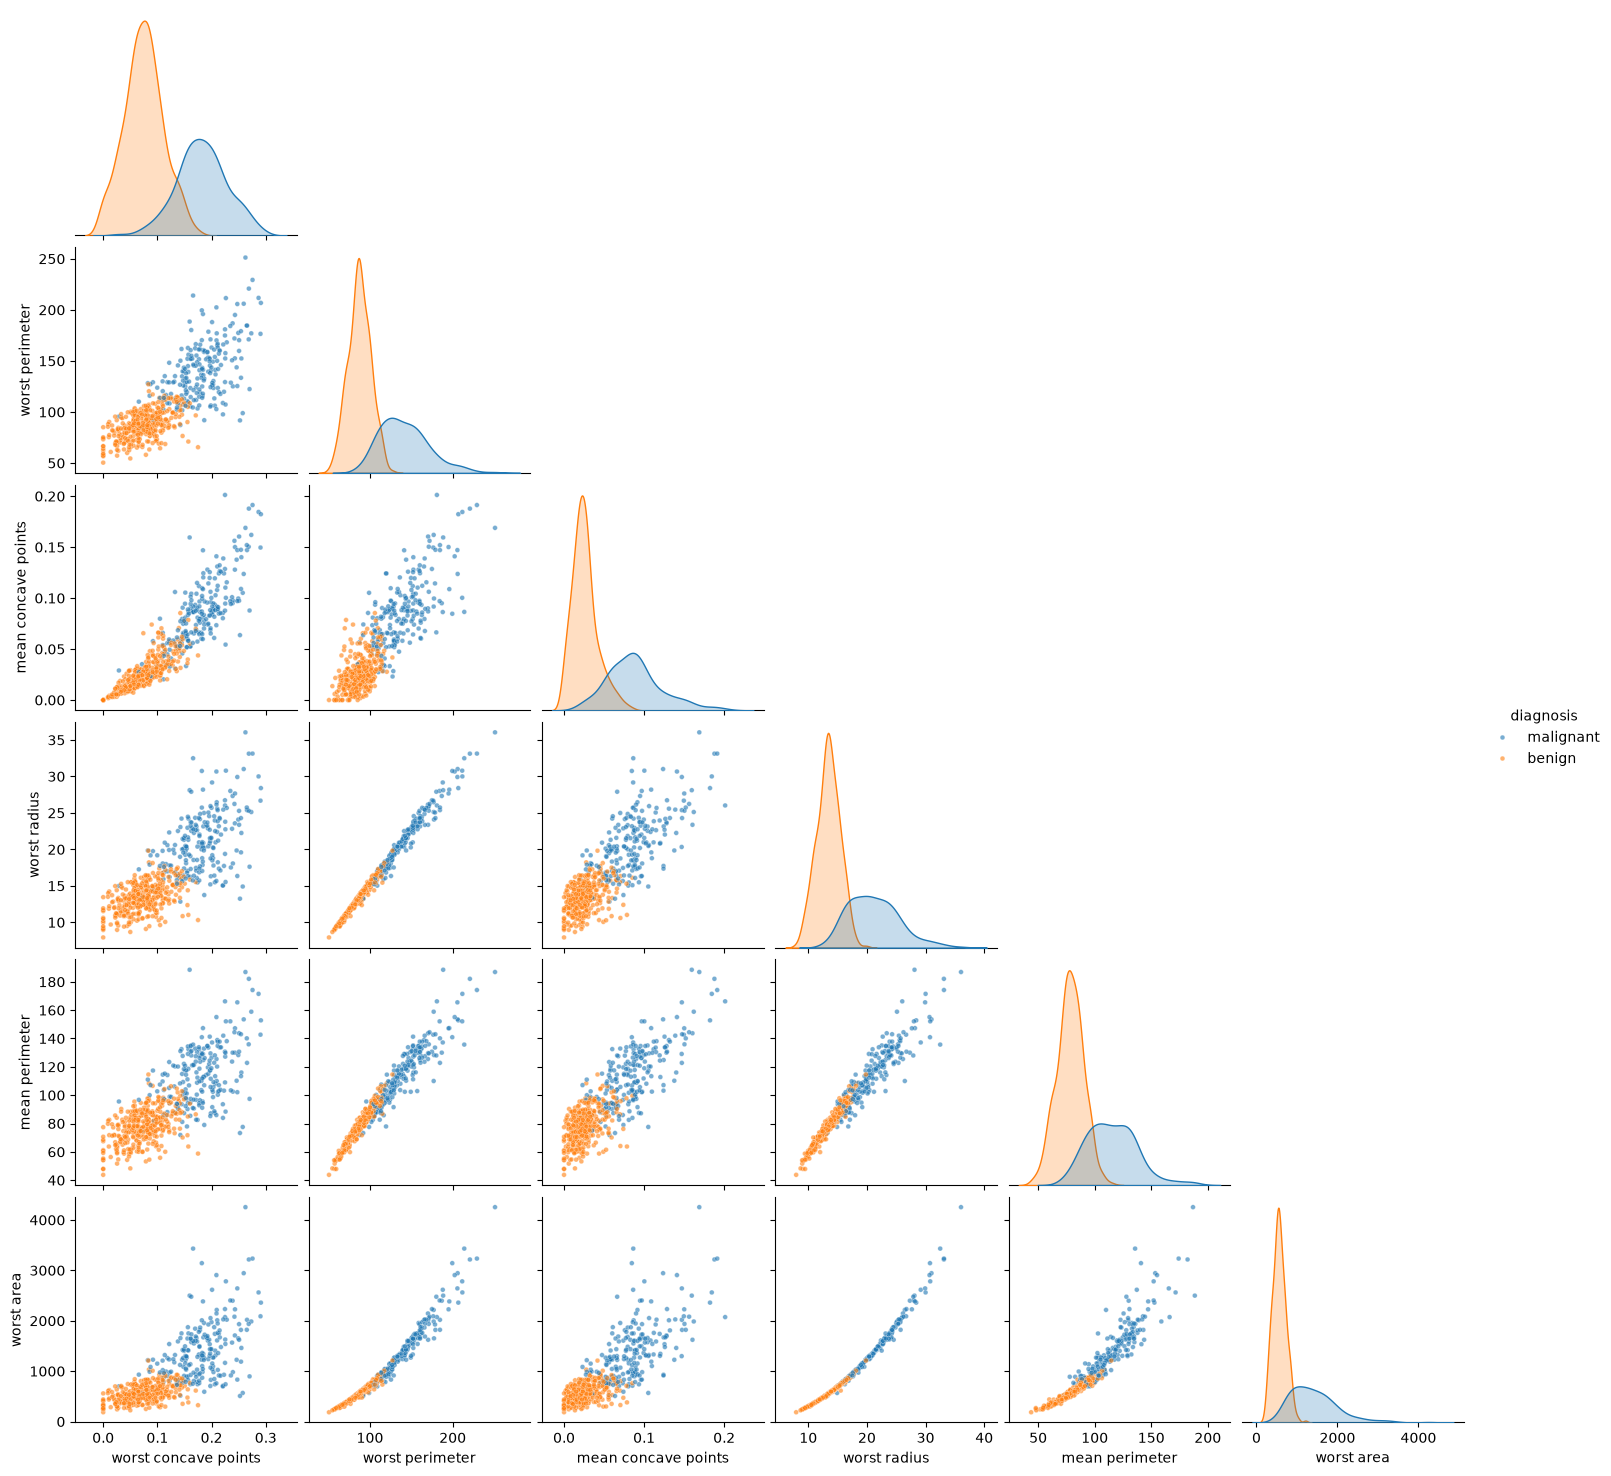

In [14]:
correlations = np.array([np.corrcoef(X[:, i], y)[0, 1] for i in range(X.shape[1])])
top_idx = np.argsort(-np.abs(correlations))[:6]
top_features = [feature_names[i] for i in top_idx]

print('Features most correlated with the target:')
print(pd.Series(correlations[top_idx], index=top_features).round(3))

sns.pairplot(
  df.loc[:, [*top_features, 'target']].assign(diagnosis=pd.Categorical.from_codes(y, class_names)).drop(columns='target'),
  hue='diagnosis',
  corner=True,
  plot_kws={'s': 12, 'alpha': 0.6},
)
plt.show()

## 3. Clustering: spectral, k-means and Gaussian mixture

In [19]:
X_scaled = StandardScaler().fit_transform(X)


def align_clusters(true_labels: np.ndarray, clusters: np.ndarray) -> np.ndarray:
  if np.mean(clusters == true_labels) < 0.5:
    return 1 - clusters

  return clusters


cluster_models = {
  'Spectral clustering': SpectralClustering(n_clusters=2, affinity='nearest_neighbors', n_neighbors=10, random_state=42),
  'k-means': KMeans(n_clusters=2, n_init='auto', random_state=42),
  'Gaussian mixture': GaussianMixture(n_components=2, covariance_type='full', n_init=5, random_state=42),
}

cluster_labels = {name: align_clusters(y, model.fit_predict(X_scaled)) for name, model in cluster_models.items()}

pd.DataFrame({
  name: {
    'accuracy vs. classes': accuracy_score(y, labels),
    'ARI': adjusted_rand_score(y, labels),
    'cluster sizes (0, 1)': str(np.bincount(labels).tolist()),
  }
  for name, labels in cluster_labels.items()
}).T

,accuracy vs. classes,ARI,"cluster sizes (0, 1)"
Spectral clustering,0.936731,0.760801,"[188, 381]"
k-means,0.912127,0.676505,"[188, 381]"
Gaussian mixture,0.940246,0.774016,"[214, 355]"


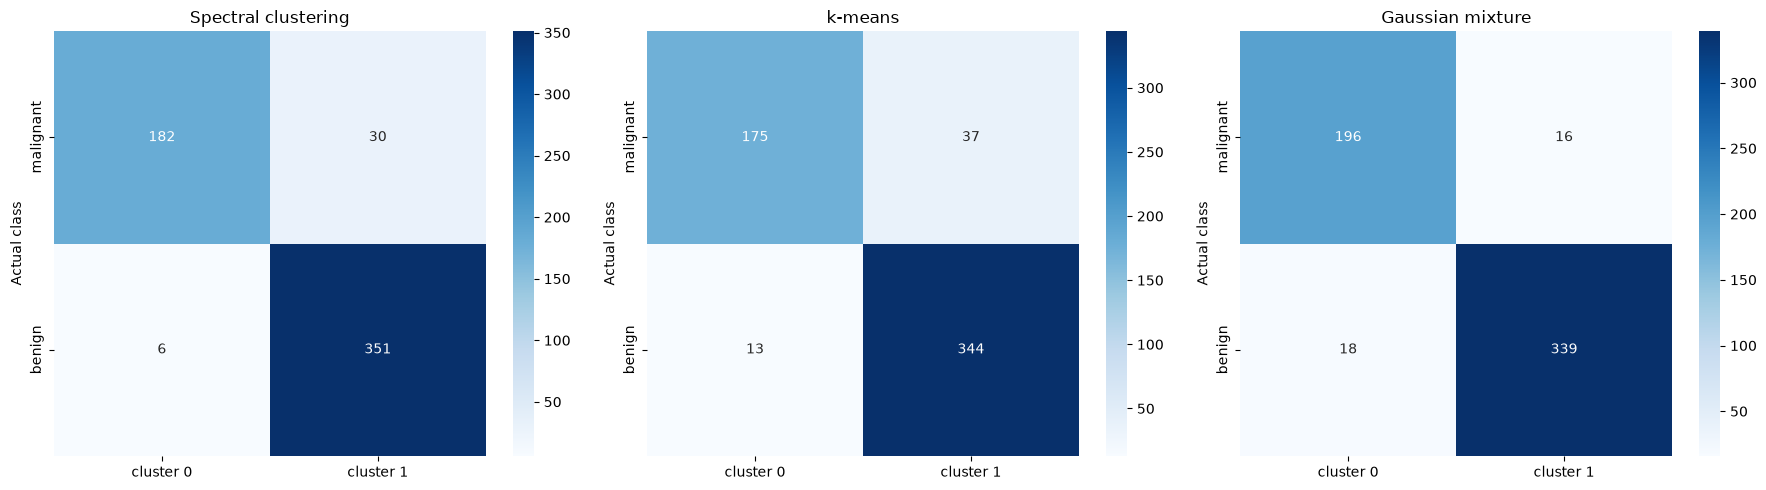

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, labels) in zip(axes, cluster_labels.items()):
  sns.heatmap(confusion_matrix(y, labels), annot=True, fmt='d', cmap='Blues',
              xticklabels=['cluster 0', 'cluster 1'], yticklabels=class_names, ax=ax)
  ax.set_title(name)
  ax.set_ylabel('Actual class')

plt.tight_layout()
plt.show()

In [24]:
gmm_types = []
for covariance_type in ['full', 'tied', 'diag', 'spherical']:
  labels = align_clusters(y, GaussianMixture(n_components=2, covariance_type=covariance_type, n_init=5, random_state=42).fit_predict(X_scaled))
  gmm_types.append({'covariance': covariance_type, 'accuracy vs. classes': accuracy_score(y, labels), 'ARI': adjusted_rand_score(y, labels)})

pd.DataFrame(gmm_types).set_index('covariance').round(3)

,accuracy vs. classes,ARI
covariance,,
full,0.940,0.774
tied,0.921,0.705
diag,0.912,0.678
spherical,0.872,0.551


## 4. Dimensionality reduction with PCA

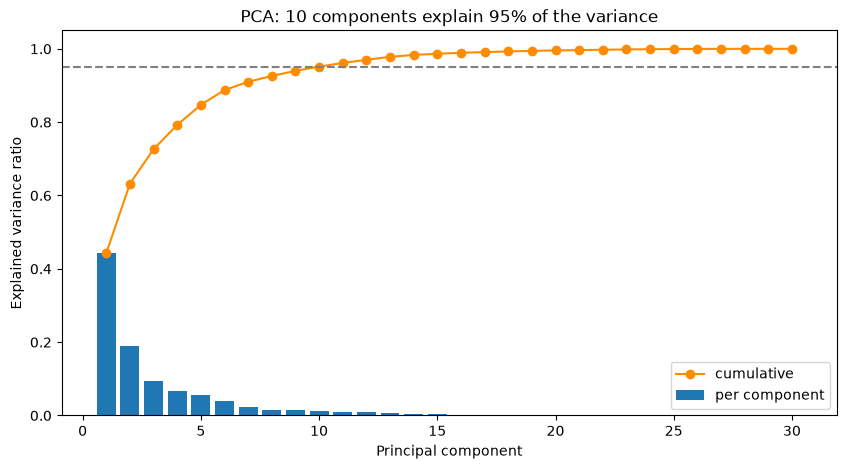

PC1 + PC2 explain 63.2 % of the variance


In [28]:
pca_full = PCA().fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = int(np.argmax(cumulative >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(1, 31), pca_full.explained_variance_ratio_, label='per component')
ax.plot(range(1, 31), cumulative, marker='o', color='darkorange', label='cumulative')
ax.axhline(0.95, color='gray', linestyle='--')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title(f'PCA: {n_95} components explain 95% of the variance')
ax.legend()
plt.show()

print('PC1 + PC2 explain', round(cumulative[1] * 100, 1), '% of the variance')

In [30]:
pca_2d_model = PCA(n_components=2).fit(X_scaled)
pca_2d = np.asarray(pca_2d_model.transform(X_scaled))
components = np.asarray(pca_2d_model.components_)
order = np.argsort(-np.abs(components[0]))[:8]

pd.DataFrame(components[:, order].T, index=np.array(feature_names)[order], columns=['PC1', 'PC2']).round(3)

,PC1,PC2
mean concave points,0.261,-0.035
mean concavity,0.258,0.060
worst concave points,0.251,-0.008
mean compactness,0.239,0.152
worst perimeter,0.237,-0.200
worst concavity,0.229,0.098
worst radius,0.228,-0.220
mean perimeter,0.228,-0.215


## 5. Classes in the new feature space

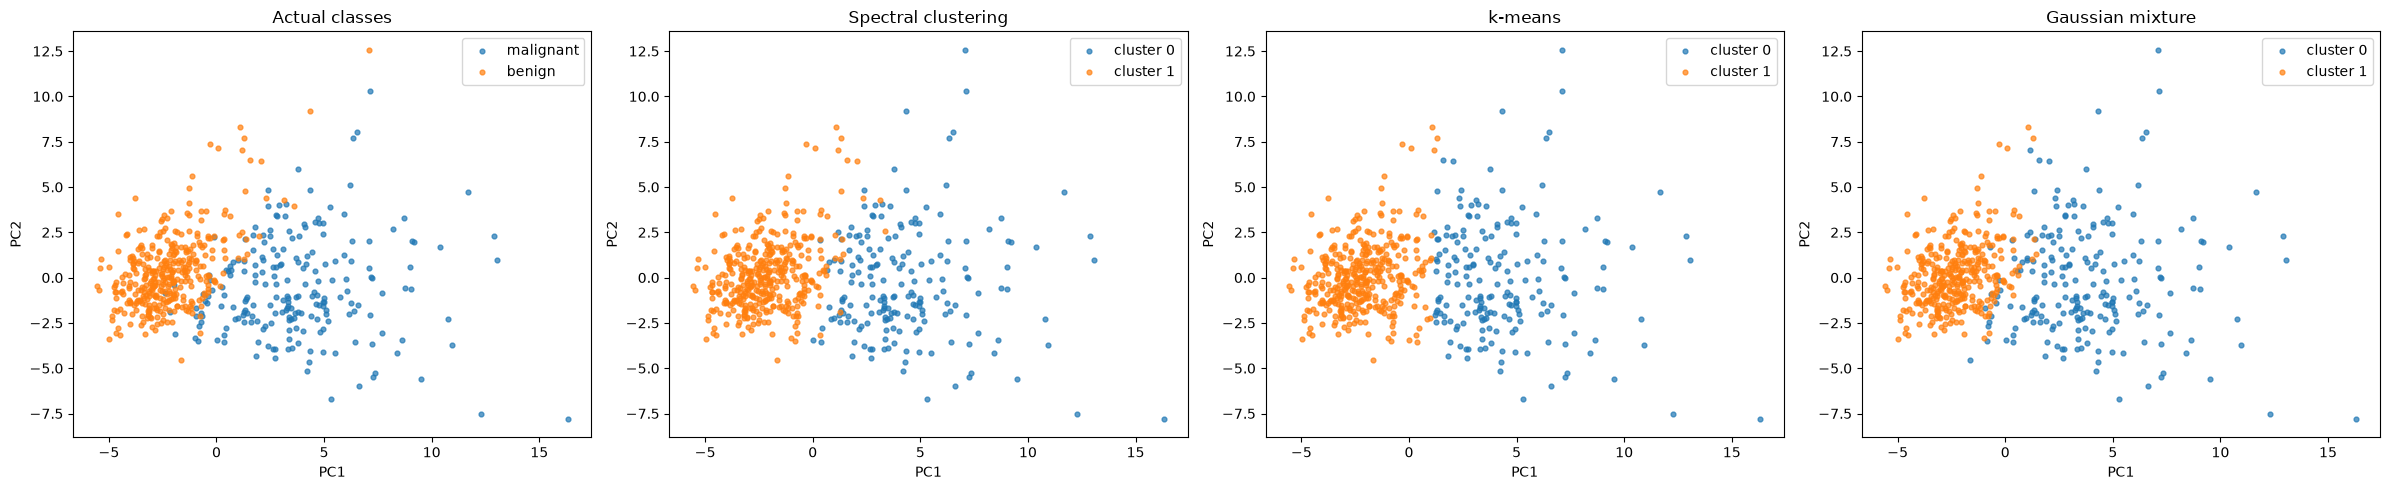

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for class_id, name in enumerate(class_names):
  mask = y == class_id
  axes[0].scatter(pca_2d[mask, 0], pca_2d[mask, 1], s=12, alpha=0.7, label=name)
axes[0].set_title('Actual classes')
axes[0].legend()

for ax, (name, labels) in zip(axes[1:], cluster_labels.items()):
  for cluster_id in range(2):
    mask = labels == cluster_id
    ax.scatter(pca_2d[mask, 0], pca_2d[mask, 1], s=12, alpha=0.7, label=f'cluster {cluster_id}')
  ax.set_title(name)
  ax.legend()

for ax in axes:
  ax.set_xlabel('PC1')
  ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

## 6. Logistic regression with sklearn

In [36]:
X_train_raw, X_test_raw, y_train, y_test = cast(
  list[np.ndarray],
  train_test_split(X, y, test_size=0.25, stratify=y, random_state=42),
)

scaler = StandardScaler().fit(X_train_raw)
X_train = np.asarray(scaler.transform(X_train_raw))
X_test = np.asarray(scaler.transform(X_test_raw))

pca = PCA(n_components=n_95).fit(X_train)
X_train_pca = np.asarray(pca.transform(X_train))
X_test_pca = np.asarray(pca.transform(X_test))

print('Train:', X_train.shape, '| Test:', X_test.shape, '| PCA features:', X_train_pca.shape[1])

Train: (426, 30) | Test: (143, 30) | PCA features: 10


In [39]:
results: list[dict[str, Any]] = []
predictions: dict[str, np.ndarray] = {}


def report(name: str, y_pred: np.ndarray, seconds: float, features: str = 'all 30') -> None:
  predictions[name] = y_pred
  results.append({
    'model': name,
    'features': features,
    'accuracy': accuracy_score(y_test, y_pred),
    'F1 (benign = 1)': f1_score(y_test, y_pred),
    'F1 (malignant)': f1_score(y_test, y_pred, pos_label=0),
    'false negatives (malignant -> benign)': int(confusion_matrix(y_test, y_pred)[0, 1]),
    'train time, ms': seconds * 1000,
  })


start = time.perf_counter()
sklearn_lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
report('sklearn LogisticRegression', sklearn_lr.predict(X_test), time.perf_counter() - start)

start = time.perf_counter()
sklearn_lr_pca = LogisticRegression(max_iter=1000).fit(X_train_pca, y_train)
report('sklearn LogisticRegression (PCA)', sklearn_lr_pca.predict(X_test_pca), time.perf_counter() - start, f'PCA {n_95}')

pd.DataFrame(results).set_index('model').round(4)

,features,accuracy,F1 (benign = 1),F1 (malignant),false negatives (malignant -> benign),"train time, ms"
model,,,,,,
sklearn LogisticRegression,all 30,0.986,0.9889,0.9811,1,2.1936
sklearn LogisticRegression (PCA),PCA 10,0.979,0.9832,0.9720,1,0.9633


## 7. Logistic regression optimized with gradient descent methods

In [42]:
L2 = 1 / len(y_train)


def sigmoid(z: np.ndarray) -> np.ndarray:
  return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def add_bias(X: np.ndarray) -> np.ndarray:
  return np.hstack([np.ones((len(X), 1)), X])


def log_loss(weights: np.ndarray, X: np.ndarray, y: np.ndarray, l2: float = 0.0) -> float:
  p = np.clip(sigmoid(X @ weights), 1e-12, 1 - 1e-12)
  penalty = l2 / 2 * np.sum(weights[1:] ** 2)

  return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + penalty)


def log_loss_gradient(weights: np.ndarray, X: np.ndarray, y: np.ndarray, l2: float = 0.0) -> np.ndarray:
  gradient = X.T @ (sigmoid(X @ weights) - y) / len(y)
  gradient[1:] += l2 * weights[1:]

  return gradient

In [48]:
def fit_logistic_regression(
  X: np.ndarray,
  y: np.ndarray,
  method: str = 'gd',
  learning_rate: float = 0.1,
  n_iter: int = 1000,
  batch_size: int = 32,
  l2: float = L2,
  beta1: float = 0.9,
  beta2: float = 0.999,
  eps: float = 1e-8,
  seed: int = 42,
) -> tuple[np.ndarray, list[float]]:
  rng = np.random.default_rng(seed)
  Xb = add_bias(X)
  weights = np.zeros(Xb.shape[1])
  m = np.zeros(Xb.shape[1])
  v = np.zeros(Xb.shape[1])
  history = []

  for t in range(1, n_iter + 1):
    if method == 'sgd':
      batch = rng.choice(len(y), batch_size, replace=False)
      gradient = log_loss_gradient(weights, Xb[batch], y[batch], l2)
    else:
      gradient = log_loss_gradient(weights, Xb, y, l2)

    if method in ('gd', 'sgd'):
      step = gradient
    elif method == 'rmsprop':
      v = beta1 * v + (1 - beta1) * gradient**2
      step = gradient / (np.sqrt(v) + eps)
    elif method in ('adam', 'nadam'):
      m = beta1 * m + (1 - beta1) * gradient
      v = beta2 * v + (1 - beta2) * gradient**2
      m_hat = m / (1 - beta1**t)
      v_hat = v / (1 - beta2**t)
      if method == 'nadam':
        m_hat = beta1 * m_hat + (1 - beta1) * gradient / (1 - beta1**t)
      step = m_hat / (np.sqrt(v_hat) + eps)
    else:
      raise ValueError(f'Unknown method: {method}')

    weights = weights - learning_rate * step
    history.append(log_loss(weights, Xb, y, l2))

  return weights, history


def predict(weights: np.ndarray, X: np.ndarray, threshold: float = 0.5) -> np.ndarray:
  return (sigmoid(add_bias(X) @ weights) >= threshold).astype(int)

In [65]:
GD_METHODS = ['gd', 'sgd', 'rmsprop', 'adam', 'nadam']
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]

lr_rows: list[dict[str, Any]] = []
for method in GD_METHODS:
  for lr in learning_rates:
    _, history = fit_logistic_regression(X_train, y_train, method=method, learning_rate=lr, n_iter=500)
    lr_rows.append({'method': method, 'learning_rate': lr, 'final train loss': history[-1]})

lr_search = pd.DataFrame(lr_rows)
lr_search.pivot(index='method', columns='learning_rate', values='final train loss').round(4)

learning_rate,0.001,0.010,0.050,0.100,0.500,1.000
method,,,,,,
adam,0.1356,0.0703,0.0681,0.0681,0.0681,0.0681
gd,0.3277,0.1291,0.0835,0.0755,0.0687,0.0682
nadam,0.1346,0.0700,0.0681,0.0681,0.0681,0.0684
rmsprop,0.0819,0.0682,0.0685,0.0698,0.0849,0.3966
sgd,0.3266,0.1294,0.0841,0.0760,0.0692,0.0697


In [67]:
best_lr: dict[str, float] = {}
for method in GD_METHODS:
  method_rows = [row for row in lr_rows if row['method'] == method]
  best_lr[method] = float(min(method_rows, key=lambda row: row['final train loss'])['learning_rate'])

best_lr

{'gd': 1.0, 'sgd': 0.5, 'rmsprop': 0.01, 'adam': 1.0, 'nadam': 0.5}

In [71]:
N_ITER = 500
gd_models: dict[str, np.ndarray] = {}
gd_histories: dict[str, list[float]] = {}

for method in GD_METHODS:
  start = time.perf_counter()
  weights, history = fit_logistic_regression(X_train, y_train, method=method, learning_rate=best_lr[method], n_iter=N_ITER)
  seconds = time.perf_counter() - start
  gd_models[method] = weights
  gd_histories[method] = history
  report(f'LR + {method.upper()} (lr={best_lr[method]})', predict(weights, X_test), seconds)

pd.DataFrame(results[-len(GD_METHODS):]).set_index('model').round(4)

,features,accuracy,F1 (benign = 1),F1 (malignant),false negatives (malignant -> benign),"train time, ms"
model,,,,,,
LR + GD (lr=1.0),all 30,0.986,0.9889,0.9811,1,12.3514
LR + SGD (lr=0.5),all 30,0.979,0.9832,0.9720,1,12.3890
LR + RMSPROP (lr=0.01),all 30,0.986,0.9889,0.9811,1,13.3481
LR + ADAM (lr=1.0),all 30,0.986,0.9889,0.9811,1,13.8969
LR + NADAM (lr=0.5),all 30,0.986,0.9889,0.9811,1,14.4182


sklearn  final loss = 0.0681
GD       final loss = 0.0682, iterations to loss < 0.1: 8, max |w - w_sklearn| = 0.126
SGD      final loss = 0.0692, iterations to loss < 0.1: 23, max |w - w_sklearn| = 0.307
RMSPROP  final loss = 0.0682, iterations to loss < 0.1: 52, max |w - w_sklearn| = 0.020
ADAM     final loss = 0.0681, iterations to loss < 0.1: 41, max |w - w_sklearn| = 0.024
NADAM    final loss = 0.0681, iterations to loss < 0.1: 43, max |w - w_sklearn| = 0.024


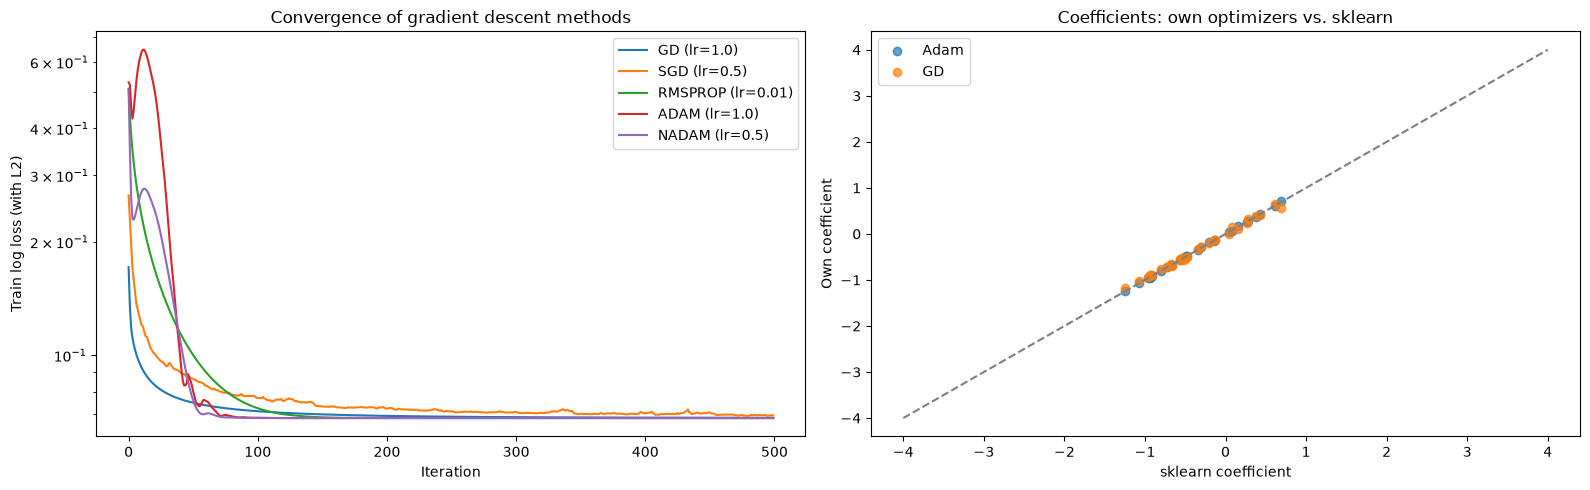

In [76]:
sklearn_weights = np.concatenate([sklearn_lr.intercept_, sklearn_lr.coef_.ravel()])
print(f'sklearn  final loss = {log_loss(sklearn_weights, add_bias(X_train), y_train, L2):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for method, history in gd_histories.items():
  axes[0].plot(history, label=f'{method.upper()} (lr={best_lr[method]})')
  iterations_to_target = next((i + 1 for i, loss in enumerate(history) if loss < 0.1), None)
  max_diff = np.abs(gd_models[method] - sklearn_weights).max()
  print(f'{method.upper():8s} final loss = {history[-1]:.4f}, iterations to loss < 0.1: {iterations_to_target}, max |w - w_sklearn| = {max_diff:.3f}')

axes[0].set_yscale('log')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Train log loss (with L2)')
axes[0].set_title('Convergence of gradient descent methods')
axes[0].legend()

coefficients = pd.DataFrame({method.upper(): weights for method, weights in gd_models.items()})
coefficients['sklearn'] = sklearn_weights
axes[1].scatter(coefficients['sklearn'], coefficients['ADAM'], label='Adam', alpha=0.7)
axes[1].scatter(coefficients['sklearn'], coefficients['GD'], label='GD', alpha=0.7)
axes[1].plot([-4, 4], [-4, 4], color='gray', linestyle='--')
axes[1].set_xlabel('sklearn coefficient')
axes[1].set_ylabel('Own coefficient')
axes[1].set_title('Coefficients: own optimizers vs. sklearn')
axes[1].legend()

plt.tight_layout()
plt.show()

In [78]:
for method in ['gd', 'adam']:
  start = time.perf_counter()
  weights, _ = fit_logistic_regression(X_train_pca, y_train, method=method, learning_rate=best_lr[method], n_iter=N_ITER)
  report(f'LR + {method.upper()} (PCA)', predict(weights, X_test_pca), time.perf_counter() - start, f'PCA {n_95}')

pd.DataFrame(results[-2:]).set_index('model').round(4)

,features,accuracy,F1 (benign = 1),F1 (malignant),false negatives (malignant -> benign),"train time, ms"
model,,,,,,
LR + GD (PCA),PCA 10,0.979,0.9832,0.972,1,11.8209
LR + ADAM (PCA),PCA 10,0.979,0.9832,0.972,1,14.3569


## 8. Logistic regression optimized with a genetic algorithm

In [82]:
def make_fitness(X: np.ndarray, y: np.ndarray, l2: float = L2) -> Any:
  Xb = add_bias(X)

  def fitness_func(ga_instance: Any, solution: np.ndarray, solution_idx: int) -> float:
    return -log_loss(solution, Xb, y, l2)

  return fitness_func


def fit_logistic_regression_ga(X: np.ndarray, y: np.ndarray, seed: int = 42, **overrides: Any) -> pygad.GA:
  params: dict[str, Any] = {
    'num_generations': 300,
    'num_parents_mating': 20,
    'sol_per_pop': 50,
    'num_genes': X.shape[1] + 1,
    'fitness_func': make_fitness(X, y),
    'init_range_low': -1.0,
    'init_range_high': 1.0,
    'parent_selection_type': 'sss',
    'keep_elitism': 2,
    'crossover_type': 'uniform',
    'mutation_type': 'random',
    'mutation_percent_genes': 20,
    'random_mutation_min_val': -0.3,
    'random_mutation_max_val': 0.3,
    'random_seed': seed,
    'suppress_warnings': True,
    **overrides,
  }
  ga = pygad.GA(**params)
  ga.run()

  return ga

GA train log loss: 0.0687 in 0.6 s, best at generation 293


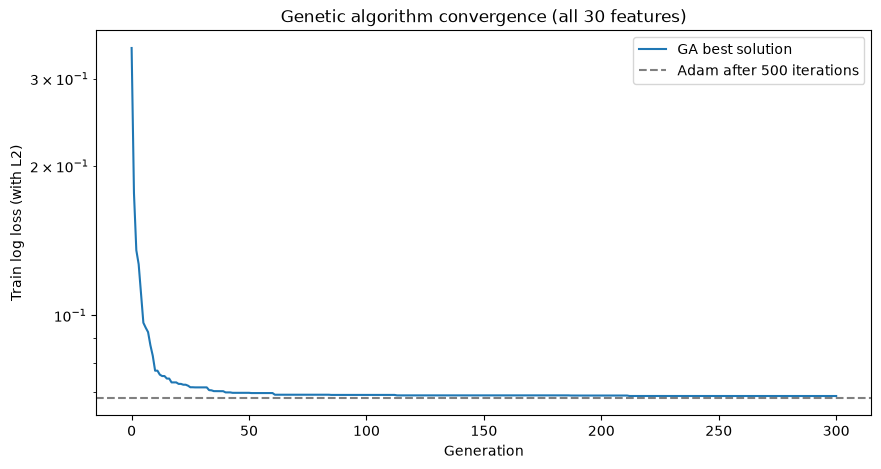

In [88]:
start = time.perf_counter()
ga_model = fit_logistic_regression_ga(X_train, y_train)
ga_seconds = time.perf_counter() - start

ga_weights, ga_fitness, _ = ga_model.best_solution()
print(f'GA train log loss: {-ga_fitness:.4f} in {ga_seconds:.1f} s, best at generation {ga_model.best_solution_generation}')
report('LR + genetic algorithm', predict(ga_weights, X_test), ga_seconds)

plt.figure(figsize=(10, 5))
plt.plot(-np.array(ga_model.best_solutions_fitness), label='GA best solution')
plt.axhline(gd_histories['adam'][-1], color='gray', linestyle='--', label='Adam after 500 iterations')
plt.yscale('log')
plt.xlabel('Generation')
plt.ylabel('Train log loss (with L2)')
plt.title('Genetic algorithm convergence (all 30 features)')
plt.legend()
plt.show()

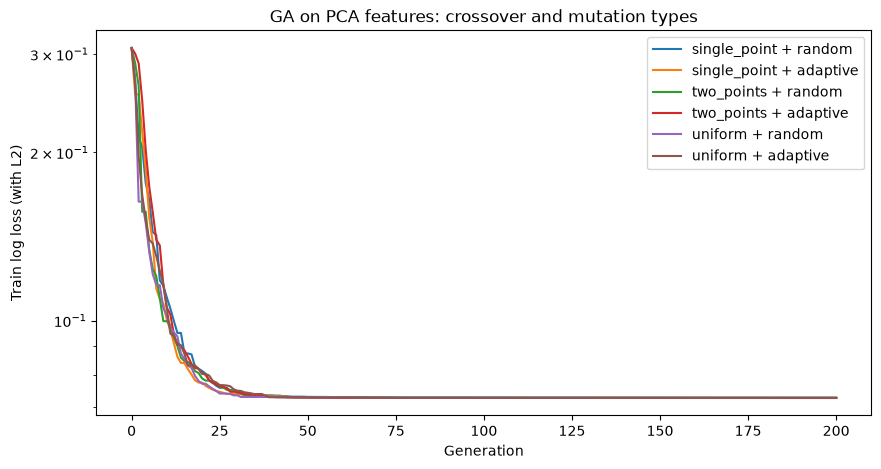

,crossover,mutation,loss @ 10 gen,loss @ 25 gen,loss @ 50 gen,final loss,generations to loss < 0.075,test F1
0,single_point,random,0.1099,0.0758,0.0730,0.0727,28,0.9832
1,single_point,adaptive,0.1001,0.0745,0.0729,0.0727,24,0.9832
2,two_points,random,0.0997,0.0760,0.0729,0.0727,29,0.9832
3,two_points,adaptive,0.1055,0.0763,0.0728,0.0727,28,0.9832
4,uniform,random,0.1019,0.0740,0.0729,0.0727,24,0.9832
5,uniform,adaptive,0.1051,0.0766,0.0728,0.0727,30,0.9832


In [97]:
ga_rows = []
ga_curves = {}
for crossover_type in ['single_point', 'two_points', 'uniform']:
  for mutation_type in ['random', 'adaptive']:
    overrides: dict[str, Any] = {'crossover_type': crossover_type, 'mutation_type': mutation_type}
    if mutation_type == 'adaptive':
      overrides['mutation_percent_genes'] = (30, 10)
    ga = fit_logistic_regression_ga(X_train_pca, y_train, num_generations=200, **overrides)
    losses = -np.array(ga.best_solutions_fitness)
    weights, _, _ = ga.best_solution()
    y_pred = predict(weights, X_test_pca)
    ga_curves[f'{crossover_type} + {mutation_type}'] = losses
    ga_rows.append({
      'crossover': crossover_type,
      'mutation': mutation_type,
      'loss @ 10 gen': losses[10],
      'loss @ 25 gen': losses[25],
      'loss @ 50 gen': losses[50],
      'final loss': losses[-1],
      'generations to loss < 0.075': int(np.argmax(losses < 0.075)) if (losses < 0.075).any() else None,
      'test F1': f1_score(y_test, y_pred),
    })

plt.figure(figsize=(10, 5))
for name, losses in ga_curves.items():
  plt.plot(losses, label=name)
plt.yscale('log')
plt.xlabel('Generation')
plt.ylabel('Train log loss (with L2)')
plt.title('GA on PCA features: crossover and mutation types')
plt.legend()
plt.show()

pd.DataFrame(ga_rows).round(4)

In [99]:
start = time.perf_counter()
ga_pca = fit_logistic_regression_ga(X_train_pca, y_train)
ga_pca_weights, ga_pca_fitness, _ = ga_pca.best_solution()
report('LR + genetic algorithm (PCA)', predict(ga_pca_weights, X_test_pca), time.perf_counter() - start, f'PCA {n_95}')
print(f'GA on PCA features: train log loss = {-ga_pca_fitness:.4f}')

GA on PCA features: train log loss = 0.0727


In [102]:
def accuracy_fitness(X: np.ndarray, y: np.ndarray) -> Any:
  Xb = add_bias(X)

  def fitness_func(ga_instance: Any, solution: np.ndarray, solution_idx: int) -> float:
    return float(accuracy_score(y, (sigmoid(Xb @ solution) >= 0.5).astype(int)))

  return fitness_func


start = time.perf_counter()
ga_accuracy = fit_logistic_regression_ga(X_train, y_train, fitness_func=accuracy_fitness(X_train, y_train))
ga_accuracy_weights, ga_accuracy_fitness, _ = ga_accuracy.best_solution()
report('LR + genetic algorithm (accuracy fitness)', predict(ga_accuracy_weights, X_test), time.perf_counter() - start)

print(f'Train accuracy: {ga_accuracy_fitness:.4f}, best at generation {ga_accuracy.best_solution_generation}')
print(f'Train log loss of these weights: {log_loss(ga_accuracy_weights, add_bias(X_train), y_train, L2):.4f}')
pd.DataFrame(results[-1:]).set_index('model').round(4)

Train accuracy: 0.9930, best at generation 66
Train log loss of these weights: 0.1820


,features,accuracy,F1 (benign = 1),F1 (malignant),false negatives (malignant -> benign),"train time, ms"
model,,,,,,
LR + genetic algorithm (accuracy fitness),all 30,0.972,0.9775,0.963,1,2127.1774


## 9. Confusion matrices and F1 scores

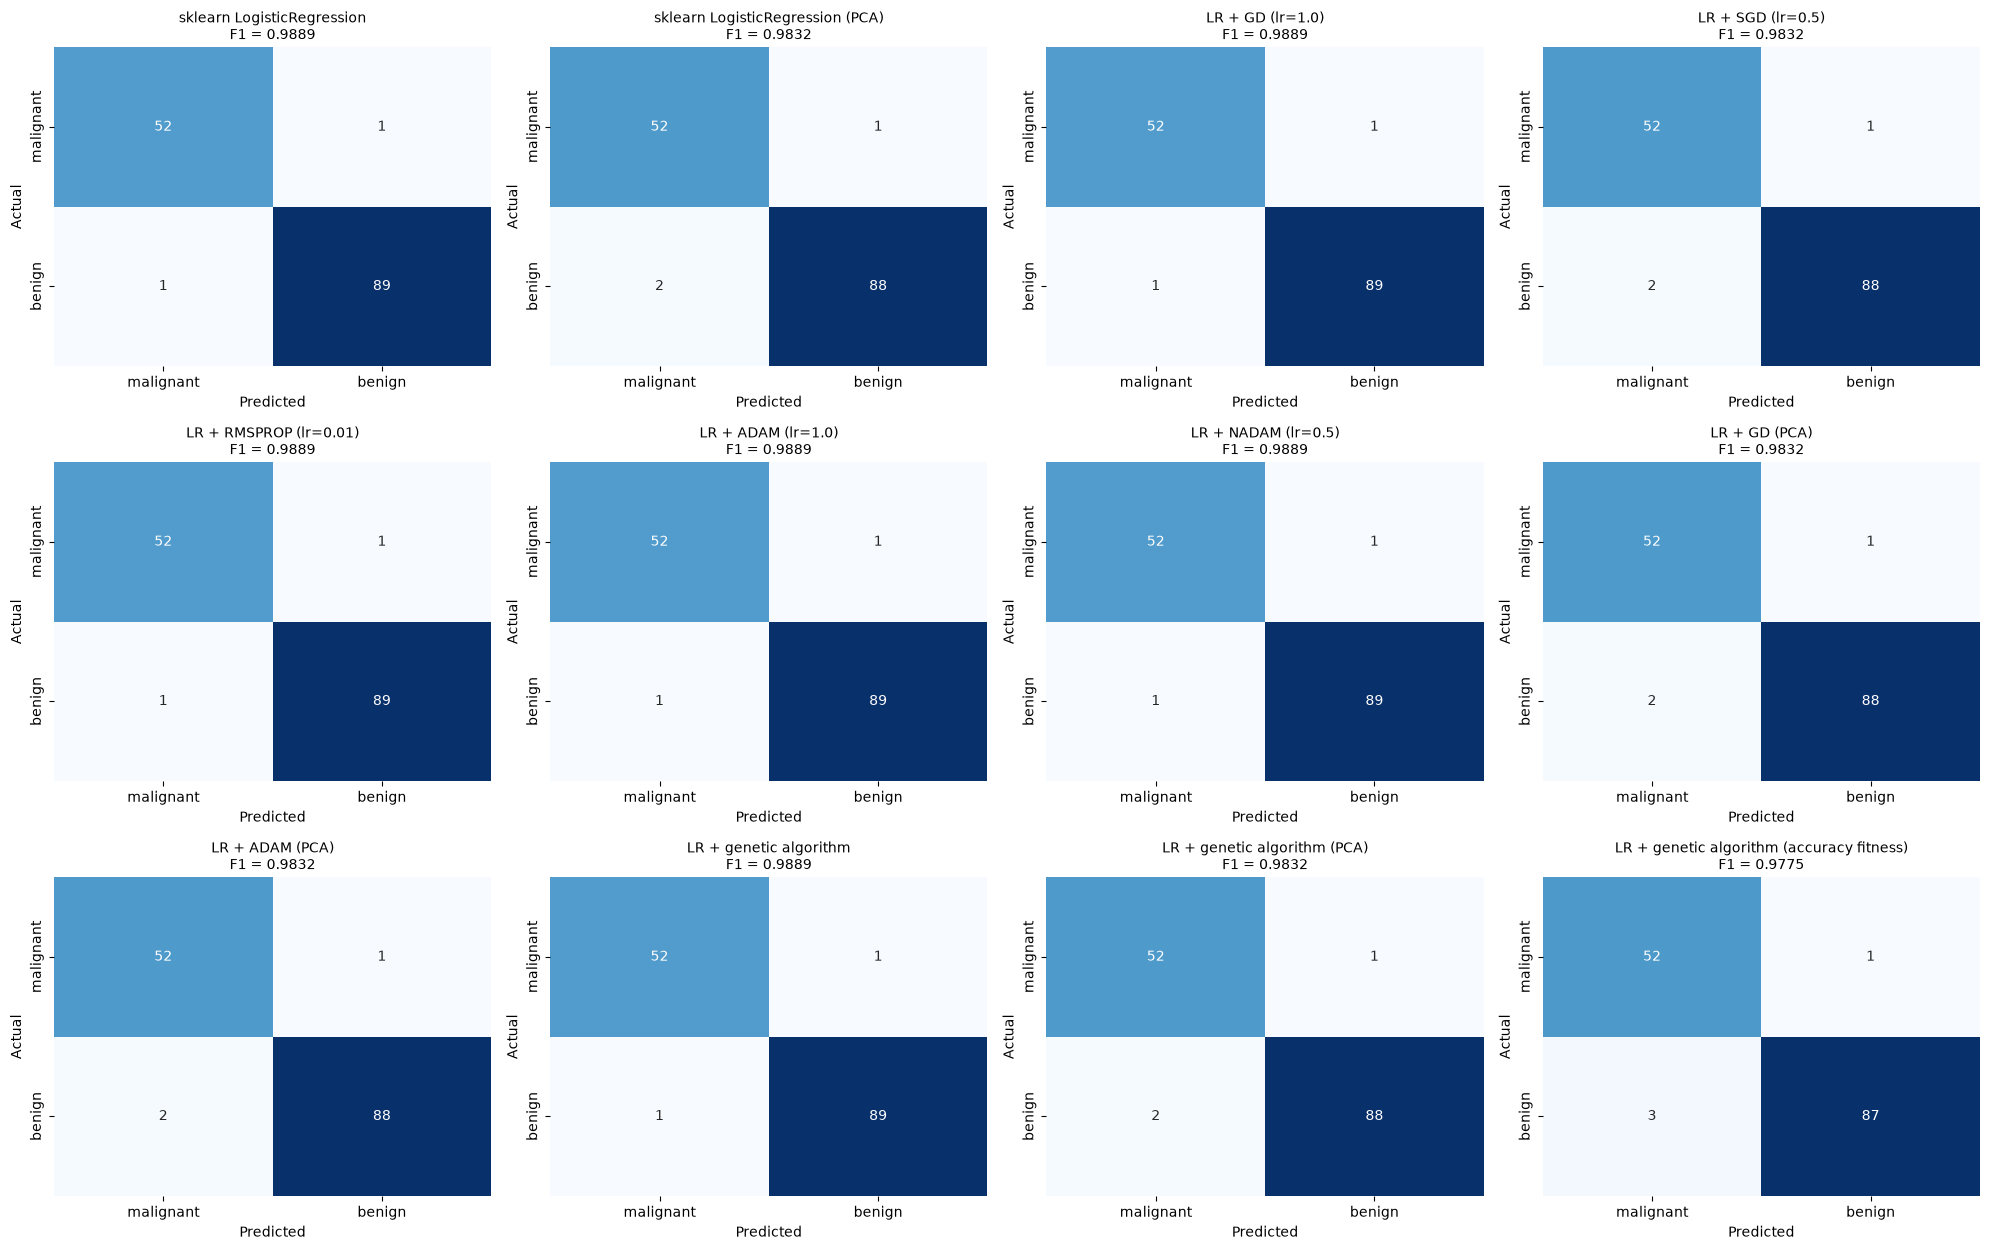

In [106]:
n_models = len(predictions)
n_cols = 4
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.2 * n_rows))
for ax in axes.ravel():
  ax.axis('off')
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
  ax.axis('on')
  sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
              xticklabels=class_names, yticklabels=class_names, ax=ax)
  ax.set_title(f'{name}\nF1 = {f1_score(y_test, y_pred):.4f}', fontsize=10)
  ax.set_xlabel('Predicted')
  ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [108]:
summary = pd.DataFrame(results).set_index('model')
summary.sort_values(['F1 (benign = 1)', 'train time, ms'], ascending=[False, True]).round(4)

,features,accuracy,F1 (benign = 1),F1 (malignant),false negatives (malignant -> benign),"train time, ms"
model,,,,,,
sklearn LogisticRegression,all 30,0.986,0.9889,0.9811,1,2.1936
LR + GD (lr=1.0),all 30,0.986,0.9889,0.9811,1,12.3514
LR + RMSPROP (lr=0.01),all 30,0.986,0.9889,0.9811,1,13.3481
LR + ADAM (lr=1.0),all 30,0.986,0.9889,0.9811,1,13.8969
LR + NADAM (lr=0.5),all 30,0.986,0.9889,0.9811,1,14.4182
LR + genetic algorithm,all 30,0.986,0.9889,0.9811,1,601.2012
sklearn LogisticRegression (PCA),PCA 10,0.979,0.9832,0.9720,1,0.9633
LR + GD (PCA),PCA 10,0.979,0.9832,0.9720,1,11.8209
LR + SGD (lr=0.5),all 30,0.979,0.9832,0.9720,1,12.3890


In [109]:
cluster_summary = pd.DataFrame({
  name: {'accuracy': accuracy_score(y, labels), 'F1 (benign = 1)': f1_score(y, labels)}
  for name, labels in cluster_labels.items()
}).T
cluster_summary.round(4)

,accuracy,F1 (benign = 1)
Spectral clustering,0.9367,0.9512
k-means,0.9121,0.9322
Gaussian mixture,0.9402,0.9522


## Conclusion

- The dataset has 569 tumours (212 malignant, 357 benign) and 30 features; size and concavity features (worst concave points, worst perimeter, mean concave points, worst radius) are the most correlated with the diagnosis (|r| ~ 0.74-0.79), and the scatter plots show the two classes separate well along them.
- Clustering without labels already recovers most of the diagnosis: Gaussian mixture 94.0% agreement (ARI 0.77), spectral clustering 93.7% (ARI 0.76), k-means 91.2% (ARI 0.68). Errors sit on the border where large benign and small malignant tumours overlap; GMM wins because its full covariance fits the elongated, unequal clusters that k-means treats as spheres.
- PCA compresses the data well: PC1 + PC2 keep 63% of the variance and 10 components keep 95%. In the PC1-PC2 plane malignant tumours spread to the right along PC1 (size and concavity), benign ones form a compact cloud.
- sklearn LogisticRegression on all 30 standardized features gives accuracy 98.6% and F1 = 0.989 (1 malignant tumour missed, 1 benign flagged); on 10 PCA components accuracy is 97.9% and F1 = 0.983.
- Own logistic regression with the same L2 penalty optimized by GD, RMSProp, Adam and Nadam reaches the same test quality as sklearn (F1 = 0.989). Adam and Nadam reach sklearn's loss (0.0681) and coefficients within 0.02-0.03; GD is fastest to reach loss < 0.1 (8 iterations with lr = 1.0) but converges slower at the end; mini-batch SGD is noisier (F1 = 0.983).
- The genetic algorithm (PyGAD, 50 chromosomes, 300 generations) reaches train loss 0.0687 on 31 weights, close to the gradient optimum, and the same F1 = 0.989, but it needs ~600 ms instead of ~13 ms and about 15,000 loss evaluations. On 10 PCA features it reaches the optimum in ~25-30 generations for every crossover and mutation type.
- The lecture variant of the GA uses accuracy as the fitness. It reaches 99.3% train accuracy but a much worse loss (0.18) and a lower test F1 = 0.978: accuracy is a step function, so the GA overfits the training set and cannot tell a confident boundary from a lucky one, while the log loss gives a smooth target.
- All optimized classifiers make at most 4 errors out of 143 test samples. The optimization method mainly changes speed, not quality: the logistic loss is convex, so gradient methods (Adam/Nadam are the most robust to the learning rate) are the right tool, while a GA is useful when the objective has no gradient.